# Historical Beta — Factors and Regressions

This notebook builds the historical daily return series of the **FF5 (Mkt-RF, SMB, HML, RMW, CMA) + Momentum (WML) + BAB** factors for the Brazilian market and uses them to estimate the historical beta of all stocks relative to the Ibovespa through rolling regressions of 1, 2 and 3 years in the **CAPM, FF3, FF5 and FF7** models (FF5 + WML + BAB).

Outputs:
- `data/ff_factors.csv.gz`: daily return series of the factors + Risk_Free (SELIC);
- `data/beta_{model}_{window}.csv.gz`: 12 dates × tickers matrices with the market beta (4 models × 3 windows);
- `factors/ivol.csv.gz`: idiosyncratic volatility (standard deviation of the FF3 residuals, 1-year window), a lower-is-better signal following the pattern of `volatility.csv.gz`.

Conventions: risk-free = SELIC; market = IBOV; equal-weight long-short portfolios with 30/70 breakpoints and monthly rebalancing, reusing the functions of `04_factor_screening.ipynb`.

In [1]:
# Library imports

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.regression.rolling import RollingOLS

import matplotlib.pyplot as plt

from datetime import date, timedelta
from tqdm import tqdm
from bizdays import Calendar, set_option

cal = Calendar.load('ANBIMA')
set_option('mode', 'pandas')

## Data import

Market data, benchmarks and the ready signals in `factors/` — including `investments.csv.gz` (minus the total asset growth, an input of the CMA factor).

In [2]:
# Imports data already collected

path = '.'
factors_folder = 'factors'
data_folder = 'data'

companies = pd.read_csv(path + "/" + data_folder + "/" + 'index_composition.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
prices_df = pd.read_csv(path + "/" + data_folder + "/" + 'prices.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volume = pd.read_csv(path + "/" + data_folder + "/" + 'volume.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
benchmarks = pd.read_csv(path + "/" + data_folder + "/" + 'benchmarks.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
nefin = pd.read_csv(path + "/" + data_folder + "/" + 'nefin_factors.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
market_value = pd.read_csv(path + "/" + data_folder + "/" + 'relative_market_value.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Factor signals
momentum = pd.read_csv(path + "/" + factors_folder + "/" + 'momentum.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
book_to_price = pd.read_csv(path + "/" + factors_folder + "/" + 'book_to_price.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
gpoa = pd.read_csv(path + "/" + factors_folder + "/" + 'gpoa.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
bab = pd.read_csv(path + "/" + factors_folder + "/" + 'bab.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
investments = pd.read_csv(path + "/" + factors_folder + "/" + 'investments.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

## Investable universe

Same filters as `04_factor_screening.ipynb`: companies in the SMLL and MLCX indices, with a valid price on the day and a 42-day median volume above the minimum. When a company has more than one ticker, the most liquid one prevails.

In [3]:
ticker_codes = [tick[0:4] for tick in sorted(companies['Ticker'].unique())]
repeated_tickers = [tick for tick in ticker_codes if ticker_codes.count(tick) > 1]
repeated_tickers = list(dict.fromkeys(repeated_tickers))

vol_median = volume.ffill(limit=1).rolling(42).median()

for tick in repeated_tickers:
    rep = volume.columns[volume.columns.str.contains(tick)]
    ticker_filter = vol_median[rep].apply(lambda r: np.where(r == r.max(), r, np.nan), axis = 1)
    vol_median[rep] = pd.DataFrame(ticker_filter.tolist(), columns = rep, index = vol_median.index)

In [4]:
# Creates a matrix with the investable companies on each rebalancing date, showing the new index composition
investable = companies.loc[companies['Index'].isin(['SMLL', 'MLCX'])].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
investable = investable.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
investable = investable.reindex(market_value.index, method='ffill')
investable.loc[:date(2009,1,2)] = investable.loc[date(2009,1,5):date(2009,1,5)].values

# Creates a dataframe showing whether the stock had a price on the day, avoiding companies that left the market
has_price = prices_df.apply(lambda col: np.where((col.isna()) | (col <= 0), np.nan, 1)).loc[investable.index]

# Creates a dataframe to filter companies with low liquidity, avoiding companies whose prices are a problem to trade
volume_filter = vol_median.apply(lambda col: np.where(col > 1000, 1, np.nan))

## Backtest functions

Imported from the `brfactors` package, the same ones used by `04_factor_screening.ipynb`: percentile selection (`get_longshort_decile`), long-short weights (`compute_longshort_weights`, only the `equal` and `market_value` schemes are needed here) and the backtest engine (`backtest_longshort`) — equal-weight, dollar-neutral, rebalancing with the d-1 signal and weight drift between rebalances, without transaction costs.

In [5]:
from brfactors.selection import get_longshort_decile
from brfactors.backtest import backtest_longshort

## Factor construction

Signals follow the higher = better convention, masked by the investable universe. Each factor is an equal-weight long-short portfolio with 30/70 breakpoints (Fama-French convention) and monthly rebalancing:

| Factor | Signal | Long / Short |
|---|---|---|
| SMB | −market value | small / big |
| HML | book-to-price | value / growth |
| RMW | GPOA (gross profit / assets) | profitable / unprofitable |
| CMA | −asset growth | conservative / aggressive |
| WML | 12-1 momentum | winners / losers |
| BAB | `bab` signal (already −beta) | low beta / high beta |

Mkt-RF is not a cross-sectional long-short: it is the IBOV return in excess of SELIC.

In [6]:
# Rebalancing dates: first business day of each month
rebalance_dates = [date(year, month, 1) for year in range(2009, 2027) for month in range(1, 13, 1)]
rebalance_dates = [cal.following(ref_date) for ref_date in rebalance_dates if ref_date < date.today()]

# Investable universe mask applied to the signals
mask = investable * has_price * volume_filter

signals = {'SMB': -(market_value * mask),
          'HML': book_to_price * mask,
          'RMW': gpoa * mask,
          'CMA': investments * mask,
          'WML': momentum * mask,
          'BAB': bab * mask}

# Long-short 30/70 backtest for each factor
factors = dict()
for name in tqdm(signals.keys()):
    short_sig, long_sig = get_longshort_decile(0.3, signals[name])
    factors[name] = backtest_longshort(prices_df, short_sig, long_sig, rebalance_dates, market_value)

In [7]:
# Consolidates the factor series and saves them in data/
ff_factors = pd.DataFrame(factors)
ff_factors.insert(0, 'Mkt_RF', benchmarks['IBOV'] - benchmarks['SELIC'])
ff_factors['Risk_Free'] = benchmarks['SELIC']

ff_factors = ff_factors.loc[rebalance_dates[0]:prices_df.index[-1]].dropna(subset = ['Mkt_RF'])
ff_factors.index.name = 'Date'

ff_factors.to_csv(path + "/" + data_folder + "/" + 'ff_factors.csv.gz')

## Factor diagnostics

Annualized statistics, correlations between the factors and validation of SMB/HML/WML against the NEFIN series of the same name (universe and methodology differ, so a high positive correlation is expected, but far from 1).

        Return p.a.  Vol p.a.  Sharpe
Mkt_RF        0.021     0.234   0.092
SMB          -0.011     0.152  -0.071
HML           0.002     0.137   0.014
RMW           0.028     0.124   0.224
CMA          -0.027     0.109  -0.250
WML           0.118     0.184   0.643
BAB           0.035     0.212   0.164

Correlation between the factors:
        Mkt_RF   SMB   HML   RMW   CMA   WML   BAB
Mkt_RF    1.00  0.08  0.34 -0.29 -0.01 -0.28 -0.62
SMB       0.08  1.00  0.41 -0.09  0.08 -0.47 -0.47
HML       0.34  0.41  1.00 -0.51  0.34 -0.59 -0.62
RMW      -0.29 -0.09 -0.51  1.00 -0.31  0.27  0.33
CMA      -0.01  0.08  0.34 -0.31  1.00 -0.10 -0.19
WML      -0.28 -0.47 -0.59  0.27 -0.10  1.00  0.55
BAB      -0.62 -0.47 -0.62  0.33 -0.19  0.55  1.00

Daily correlation with NEFIN (2009-01-02 to 2025-06-02):
SMB    0.69
HML    0.47
WML    0.68
dtype: float64


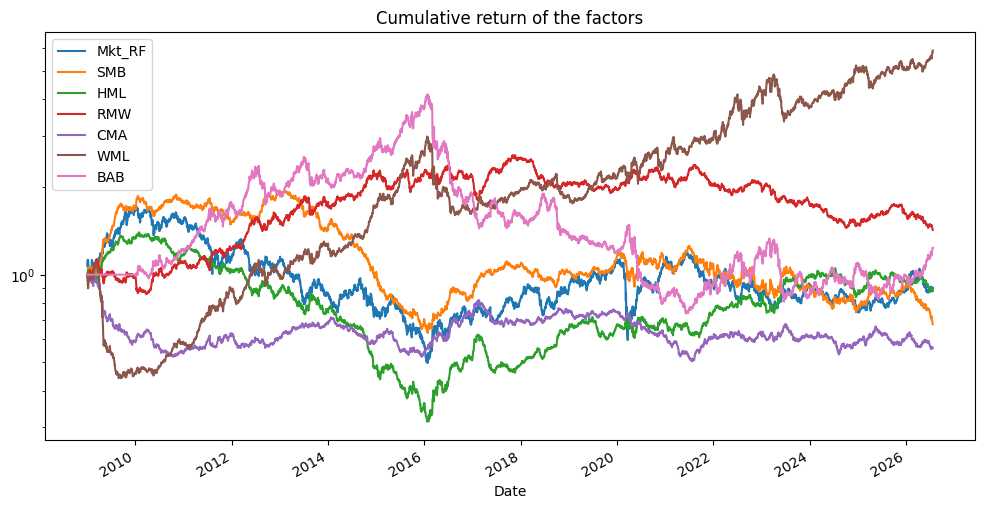

In [8]:
factor_cols = ['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA', 'WML', 'BAB']

stats_df = pd.DataFrame({'Return p.a.': ff_factors[factor_cols].mean() * 252,
                         'Vol p.a.': ff_factors[factor_cols].std() * np.sqrt(252)})
stats_df['Sharpe'] = stats_df['Return p.a.'] / stats_df['Vol p.a.']
print(stats_df.round(3))

print('\nCorrelation between the factors:')
print(ff_factors[factor_cols].corr().round(2))

# Validation against NEFIN
comp = pd.merge(ff_factors[['SMB', 'HML', 'WML']], nefin[['SMB', 'HML', 'WML']],
                left_index = True, right_index = True, suffixes = ('', '_nefin')).dropna()
print('\nDaily correlation with NEFIN ({} to {}):'.format(comp.index[0].date(), comp.index[-1].date()))
print(pd.Series({f: comp[f].corr(comp[f + '_nefin']) for f in ['SMB', 'HML', 'WML']}).round(2))

ff_factors[factor_cols].add(1).cumprod().plot(figsize = (12, 6), title = 'Cumulative return of the factors', logy = True)
plt.show()

## Rolling regressions per stock

For each stock, the daily return in excess of SELIC is regressed on the factors in rolling windows of 252, 504 and 756 business days:

- **CAPM**: Mkt_RF — **FF3**: + SMB, HML — **FF5**: + RMW, CMA — **FF7**: + WML, BAB.

Methodological notes:
- The window counts the stock's days with a return: only the days before its first price are removed before the regression. Prices are forward-filled, so days without trading enter with a zero return.
- The `Mkt_RF` coefficient (market beta) of each model/window is kept.
- **IVOL** (idiosyncratic volatility, Ang, Hodrick, Xing & Zhang 2006): standard deviation of the residuals of the 1-year FF3 regression, obtained through the identity `var(residuals) = (1 − R²)·var(y)` — with an intercept, `Σ residuals² = (1 − R²)·Σ(y − ȳ)²` holds, so the result is identical to calculating the 252 residuals of each window and taking their standard deviation; R² is used because `RollingOLS` does not expose the residual vector per window. Annualized by √252 and saved raw (lower = better), following the pattern of `volatility.csv.gz`.

In [9]:
models = {'capm': ['Mkt_RF'],
           'ff3': ['Mkt_RF', 'SMB', 'HML'],
           'ff5': ['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA'],
           'ff7': ['Mkt_RF', 'SMB', 'HML', 'RMW', 'CMA', 'WML', 'BAB']}
windows = {'1y': 252, '2y': 504, '3y': 756}

# Daily return in excess of SELIC, over the period covered by the factors
ret_excess = prices_df.pct_change(fill_method = None).sub(benchmarks['SELIC'], axis = 0).loc[ff_factors.index]

betas = {(m, j): pd.DataFrame(index = ff_factors.index, columns = prices_df.columns, dtype = float) for m in models for j in windows}
ivol = pd.DataFrame(index = ff_factors.index, columns = prices_df.columns, dtype = float)

for ticker in tqdm(prices_df.columns):
    y = ret_excess[ticker].dropna()
    if len(y) < 252:
        continue

    for m, cols in models.items():
        regression_data = pd.concat([y, ff_factors[cols]], axis = 1).dropna()

        for j, window in windows.items():
            if len(regression_data) < window:
                continue

            is_ivol = (m == 'ff3') & (j == '1y')
            res = RollingOLS(regression_data[ticker], sm.add_constant(regression_data[cols]), window = window).fit(params_only = not is_ivol)
            betas[(m, j)][ticker] = res.params['Mkt_RF']

            if is_ivol:
                # IVOL: std of the window's residuals via the identity var(residuals) = (1 - R²) · var(y)
                # clip(lower=0) protects against R² marginally > 1 due to floating point error
                var_y = regression_data[ticker].rolling(window).var()
                ivol[ticker] = np.sqrt(((1 - res.rsquared) * var_y).clip(lower = 0)) * np.sqrt(252)

In [10]:
# Saves the 12 beta matrices in data/ and IVOL in factors/
for (m, j), df_beta in betas.items():
    df_beta.dropna(how = 'all').to_csv(path + "/" + data_folder + "/" + 'beta_{0}_{1}.csv.gz'.format(m, j))

ivol.dropna(how = 'all').to_csv(path + "/" + factors_folder + "/" + 'ivol.csv.gz')

## Beta sanity checks

Checks: cross-sectional distribution on the last date, comparison with the Frazzini-Pedersen beta (from the `bab` signal), smoothness of the longer windows and IVOL ≤ total volatility.

In [11]:
last_date = betas[('capm', '1y')].dropna(how = 'all').index[-1]
latest = betas[('capm', '1y')].loc[last_date].dropna()
print('CAPM beta 1y on {} (n = {}):'.format(last_date.date(), len(latest)))
print(latest.describe().round(3))

# CAPM beta vs Frazzini-Pedersen beta (the bab signal is -beta)
beta_fp = -bab.loc[last_date]
comp_beta = pd.concat([latest, beta_fp], axis = 1, keys = ['capm_1y', 'frazzini_pedersen']).dropna()
print('\nRank-corr beta CAPM 1y vs Frazzini-Pedersen:', comp_beta['capm_1y'].rank().corr(comp_beta['frazzini_pedersen'].rank()).round(2))

# Longer windows should be smoother (lower time-series standard deviation)
print('\nAverage time-series standard deviation of the CAPM beta by window:')
for j in windows:
    print('  {}: {:.3f}'.format(j, betas[('capm', j)].std().mean()))

# IVOL must never exceed the stock's total volatility in the same window
vol_total = ret_excess.rolling(252).std() * np.sqrt(252)
exceeds = (ivol > vol_total + 1e-8).sum().sum()
print('\nCases of IVOL > total vol (expected 0):', exceeds)

CAPM beta 1y on 2026-07-23 (n = 420):
count    420.000
mean       0.538
std        0.606
min       -0.355
25%       -0.000
50%        0.309
75%        1.026
max        2.346
Name: 2026-07-23 00:00:00, dtype: float64

Rank-corr beta CAPM 1y vs Frazzini-Pedersen: 0.84

Average time-series standard deviation of the CAPM beta by window:
  1y: 0.321
  2y: 0.263
  3y: 0.222



Cases of IVOL > total vol (expected 0): 0
